# ID Without a Card: Catching Cardless Withdrawal Fraud at the Teller Line

**Author:** Mir Fuad — TD Bank, Associate Banker II (teller line), moving into data analytics
**Dataset:** Zenodo record 21511985, v7 — "A Deployment-Derived Online Banking Fraud Detection Inference-Log Dataset from a Live Cloud-Based Deep Learning System", https://doi.org/10.5281/zenodo.20030064 — Open access, CC BY 4.0, published July 23, 2026
**No Kaggle, no synthetic data, no TD customer data.** The dataset is public. The teller observations are my own, anonymised, with no customer names, account numbers, amounts from real customers, or anything copied from TD systems.

## The question

**How can a bank spot a fraudulent ID-based cash withdrawal made without a card, before the money leaves the branch, without blocking so many legitimate customers that the teller line stops moving?**

## ⚠️ Read this first — the perfect-score warning

The four ML models in the earlier fraud project score **precision = recall = F1 = PR-AUC = 1.000** on the 20-fraud test set. That is **not** production performance. It is a dataset artefact: v12, v14 and v17 each have single-feature AUC near 1.000, and amount alone has AUC 0.996, so fraud is near-perfectly separable in this demo file. The honest comparator in this notebook is a simple amount rule — flag everything at or above a dollar threshold — and what it catches and freezes on the same test set. No new ML model is built here, because a fifth model would add nothing on data that is already separable.

## 1. The question — why it matters to a bank

A missed fraud loses money. A false block strands a real customer — often an older one who lost or forgot a card and has no card to fall back on. Both errors cost the bank, and both happen at the teller line, not in a back office.

That is the trade-off in one line: catch the fraud before the cash leaves, without freezing so many legitimate customers that the line stops moving.

## 2. What the teller sees — one case, labelled as one case

Every day, customers withdraw cash with ID only, no card. Most are older customers who lost or forgot a card.

One case, mid-November 2026: a man in his 20s, dressed as an older man, tried to withdraw money with an ID that looked fake — the photo, the feel of it, and the way he acted when asked follow-up questions did not fit together. I stopped the withdrawal. No money left the branch.

That is one case, not a rate. I am not claiming this happens a certain number of times a week, because I do not have that count and TD internal data is not used here.

Why an office analyst would miss it: in a database, a completed withdrawal is an amount, an account and a time. The analyst does not see the person, the ID in hand, the mismatch between the face and the photo, or how the person acts when questioned. The fraud signal here is at the counter, not in a database row. A model can score the amount; only the teller sees the presentation.

## 3. What public data can say — the amount signal

Full EDA is in `eda/EDA_REPORT.md`; these numbers are re-used from it, not re-run for show.

- **56,962 rows, January 2026. 98 frauds (0.172%).**
- **Amount dominates:** median fraud $15,122 vs legitimate $33. Mean fraud $24,195 vs legitimate $171.
- **78 of 98 frauds are $5,000 or more.** In the $5,000+ bin, 35.8% of transactions are fraud; under $100, 0% are fraud. Fraud is $2,371,116 — 19.6% of all dollars in the file.
- **No hour pattern:** fraud rate by hour is flat (0.04%–0.35%).

The code below recomputes the fraud rate by amount bin, in pandas, with the SQL equivalent written out alongside it — because the bin table is the evidence the amount rule rests on.

In [1]:
import numpy as np, pandas as pd, json, os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

DATA = "data/fraud_tests_export.csv"   # run from the project folder
df = pd.read_csv(DATA)
print(df.shape)
print(f"Fraud: {int(df['is_fraud'].sum())} of {len(df)} ({df['is_fraud'].mean():.4%})")
print(df.groupby("is_fraud")["amount"].agg(["count", "median", "mean"]).round(2).to_string())

# Fraud rate by amount bin — full dataset
bins = [0, 100, 1000, 5000, 10000, 1e9]
labels = ["<$100", "$100-999", "$1,000-4,999", "$5,000-9,999", "$10,000+"]
df["amt_bin"] = pd.cut(df["amount"], bins=bins, labels=labels)
ab = df.groupby("amt_bin", observed=True).agg(n=("is_fraud", "size"), fraud=("is_fraud", "sum"))
ab["rate"] = (ab["fraud"] / ab["n"]).round(4)
print("\nFraud rate by amount bin (full dataset):")
print(ab.to_string())

(56962, 39)
Fraud: 98 of 56962 (0.1720%)
          count    median      mean
is_fraud                           
0         56864     32.99    171.22
1            98  15121.88  24195.06

Fraud rate by amount bin (full dataset):
                  n  fraud    rate
amt_bin                           
<$100         41528      0  0.0000
$100-999      13636      3  0.0002
$1,000-4,999   1580     17  0.0108
$5,000-9,999    109     15  0.1376
$10,000+        109     63  0.5780


### The same bin table, in SQL

```sql
SELECT
    CASE
        WHEN amount < 100 THEN '<$100'
        WHEN amount < 1000 THEN '$100-999'
        WHEN amount < 5000 THEN '$1,000-4,999'
        WHEN amount < 10000 THEN '$5,000-9,999'
        ELSE '$10,000+'
    END AS amt_bin,
    COUNT(*) AS n,
    SUM(is_fraud) AS fraud,
    CAST(SUM(is_fraud) AS FLOAT) / COUNT(*) AS fraud_rate
FROM fraud_tests_export
GROUP BY amt_bin
ORDER BY MIN(amount);
```

The point of the table is not the SQL — it is that fraud is concentrated in large amounts. That is the only signal this dataset can give about a cardless withdrawal, and it is a weak one on its own: most large transactions are still legitimate.

## 4. What public data cannot say

This dataset has **no ID field, no card-present field, no branch field, and no face / photo field**. It cannot test ID withdrawals directly, and it cannot test the checklist in section 5.

Columns in the file: `transaction_id, amount, time_value, v1`–`v28, is_fraud, fraud_probability, risk_level, recommendation, confidence, response_time_ms, timestamp, ip_address`.

- `fraud_probability`, `risk_level`, `recommendation`, `confidence` are **leakage** — outputs of the system that already made a fraud decision (HIGH risk is 91.8% fraud). They are excluded, as are `response_time_ms`, `transaction_id`, `timestamp`, `ip_address`.
- Usable features only: `amount`, `time_value`, `v1`–`v28`.
- `v1`–`v28` are anonymised, so no feature story can be told beyond their statistical separation.

What this project can prove: (a) what the amount signal looks like in public data, (b) what a teller actually checks, and (c) where the two leave a gap. That gap is the finding, not a failure to hide.

## 5. The teller checklist — the original contribution

This is a process artefact, built from what I actually check at the counter, not a dataset. Each step says what it catches and what it costs in time. No catch rate is claimed for it — there is no labelled data to measure one, and I am not inventing one.

In [2]:
checklist = pd.DataFrame([
    {"Step": 1, "Check": "Face vs photo on the ID",
     "What it catches": "Impersonation — the person does not match the photo",
     "Cost": "Seconds, if the photo is clear"},
    {"Step": 2, "Check": "ID details — feel, print, expiry, photo quality",
     "What it catches": "A fake or altered ID",
     "Cost": "Seconds to a minute"},
    {"Step": 3, "Check": "Account knowledge questions",
     "What it catches": "Someone who has an ID but does not know the account",
     "Cost": "A minute; the customer may get annoyed"},
    {"Step": 4, "Check": "Amount vs the customer's usual pattern, as the teller knows it",
     "What it catches": "An unusually large withdrawal for this customer",
     "Cost": "Seconds if the teller knows the customer; longer if not"},
    {"Step": 5, "Check": "Behaviour when questioned",
     "What it catches": "Evasiveness, rushing, changing the story",
     "Cost": "A minute or two"},
    {"Step": 6, "Check": "Escalate to a supervisor before cash leaves",
     "What it catches": "Anything above that still does not add up",
     "Cost": "Several minutes and a wait for the customer"},
])
print(checklist.to_string(index=False))
checklist.to_csv("results/teller_checklist.csv", index=False)

 Step                                                          Check                                     What it catches                                                    Cost
    1                                        Face vs photo on the ID Impersonation — the person does not match the photo                          Seconds, if the photo is clear
    2                ID details — feel, print, expiry, photo quality                                A fake or altered ID                                     Seconds to a minute
    3                                    Account knowledge questions Someone who has an ID but does not know the account                  A minute; the customer may get annoyed
    4 Amount vs the customer's usual pattern, as the teller knows it     An unusually large withdrawal for this customer Seconds if the teller knows the customer; longer if not
    5                                      Behaviour when questioned            Evasiveness, rushing, changing the 

## 6. The model, honestly — the amount rule at three thresholds

No new ML model. The four existing models (Logistic Regression, Random Forest, XGBoost, LightGBM — full results in `results/metrics.json`) all score 1.000 precision / recall / F1 / PR-AUC on the 20-fraud test set, for the artefact reasons in the warning above.

The realistic comparator is a rule any branch system could run: **flag the withdrawal if the amount is at or above a threshold.** The code below runs it at $1,000, $5,000 and $10,000 on the exact same held-out test set as the original project — stratified 80/20 split, `random_state=42`, test set 11,393 rows with 20 frauds and 11,373 legitimate transactions. The $5,000 row is checked against `results/metrics.json` in code.

In [3]:
FEATURES = ["amount", "time_value"] + [f"v{i}" for i in range(1, 29)]
X, y = df[FEATURES], df["is_fraud"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, fraud={int(y_train.sum())}")
print(f"Test:  {X_test.shape}, fraud={int(y_test.sum())}, legit={int((y_test == 0).sum())}")

rows = []
for thr in [1000, 5000, 10000]:
    pred = (X_test["amount"] >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"threshold_usd": thr, "rule": f"amount >= ${thr:,}",
        "tp_frauds_caught": int(tp), "fn_frauds_missed": int(fn),
        "fp_legit_frozen": int(fp), "tn_legit_passed": int(tn),
        "precision": round(float(precision_score(y_test, pred, zero_division=0)), 3),
        "recall": round(float(recall_score(y_test, pred, zero_division=0)), 3),
        "f1": round(float(f1_score(y_test, pred, zero_division=0)), 3),
        "frauds_caught_per_100_legit_frozen": round(float(tp / fp * 100), 1) if fp else None})
table = pd.DataFrame(rows)
print(table.to_string(index=False))
# Verification: $5,000 row must match the original metrics.json
m = json.load(open("results/metrics.json"))["test_metrics_at_0.5"]["Amount >= $5,000 rule"]
r5 = rows[1]
assert (r5["tp_frauds_caught"], r5["fn_frauds_missed"], r5["fp_legit_frozen"]) == (m["tp"], m["fn"], m["fp"])
assert abs(r5["precision"] - round(m["precision"], 3)) < 0.001 and r5["recall"] == m["recall"]
print("\n$5,000 row matches results/metrics.json exactly: TP 13, FN 7, FP 17, P 0.433, R 0.65")
table.to_csv("results/amount_rule_thresholds.csv", index=False)
json.dump({"split": {"test_size": 0.20, "stratify": True, "random_state": 42,
                     "test_rows": int(len(X_test)), "test_fraud": int(y_test.sum()),
                     "test_legit": int((y_test == 0).sum())}, "thresholds": rows},
          open("results/amount_rule_thresholds.json", "w"), indent=2)

Train: (45569, 30), fraud=78
Test:  (11393, 30), fraud=20, legit=11373
 threshold_usd              rule  tp_frauds_caught  fn_frauds_missed  fp_legit_frozen  tn_legit_passed  precision  recall    f1  frauds_caught_per_100_legit_frozen
          1000  amount >= $1,000                19                 1              310            11063      0.058    0.95 0.109                                 6.1
          5000  amount >= $5,000                13                 7               17            11356      0.433    0.65 0.520                                76.5
         10000 amount >= $10,000                11                 9                5            11368      0.688    0.55 0.611                               220.0

$5,000 row matches results/metrics.json exactly: TP 13, FN 7, FP 17, P 0.433, R 0.65


### Reading the table

- **$1,000 — high recall:** catches 19 of 20 frauds, but freezes **310 legitimate** transactions to do it. In a branch, that is 310 customers who cannot get their money. The line stops moving.
- **$5,000 — the middle:** catches 13 of 20, freezes 17. Precision 0.433, recall 0.65, F1 0.520.
- **$10,000 — high precision:** catches 11 of 20, freezes only 5. Precision 0.688, recall 0.55, F1 0.611 — the best F1 of the three, but 9 of 20 frauds walk out.

Each test fraud is 5 percentage points of recall, so do not over-read a difference of one or two frauds. The shape of the trade-off is the finding, not the exact F1.

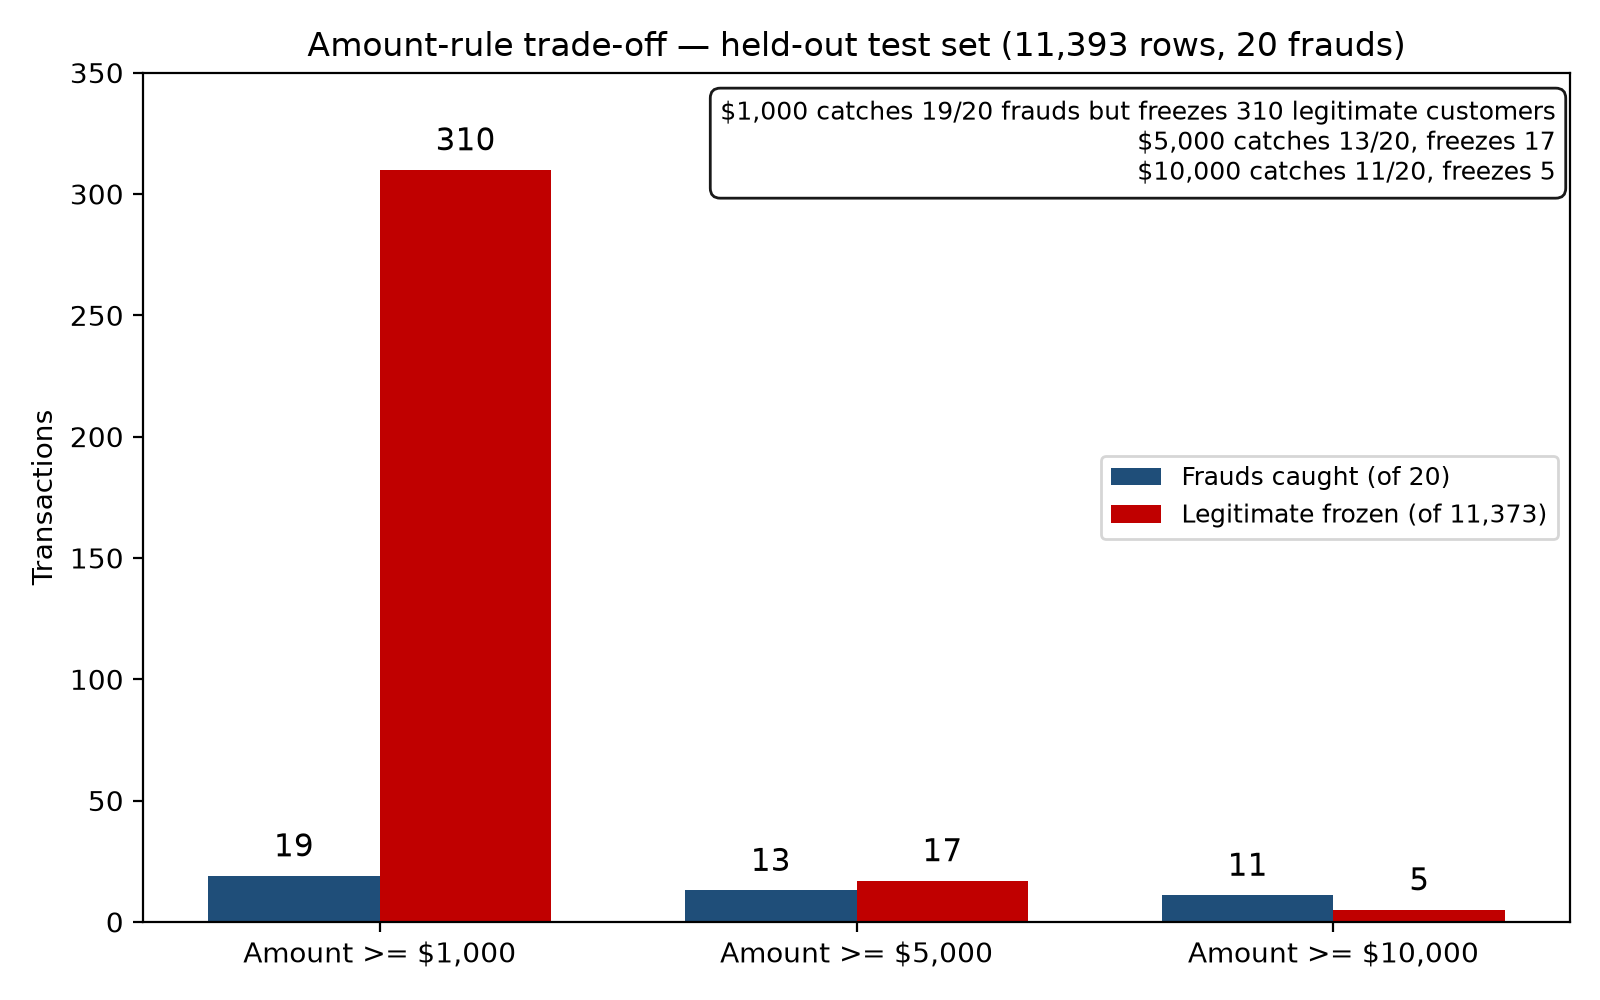

In [4]:
# One new chart: frauds caught vs legitimate frozen at the three thresholds
thr_labels = ["$1,000", "$5,000", "$10,000"]
caught = [19, 13, 11]
frozen = [310, 17, 5]
import numpy as np
x = np.arange(3); w = 0.36
fig, ax = plt.subplots(figsize=(8, 5))
b1 = ax.bar(x - w/2, caught, w, label="Frauds caught (of 20)", color="#1f4e79")
b2 = ax.bar(x + w/2, frozen, w, label="Legitimate frozen (of 11,373)", color="#c00000")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 8, str(int(b.get_height())), ha="center", fontsize=11)
ax.set_xticks(x); ax.set_xticklabels([f"Amount >= {t}" for t in thr_labels])
ax.set_ylabel("Transactions"); ax.set_ylim(0, 350)
ax.set_title("Amount-rule trade-off — held-out test set (11,393 rows, 20 frauds)")
ax.legend(fontsize=9)
ax.text(0.99, 0.97, "$1,000 catches 19/20 frauds but freezes 310 legitimate customers\n$5,000 catches 13/20, freezes 17\n$10,000 catches 11/20, freezes 5",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9))
plt.tight_layout(); plt.savefig("results/charts/amount_rule_tradeoff.png", dpi=200); plt.close()
from IPython.display import Image, display as _display
_display(Image(filename="results/charts/amount_rule_tradeoff.png"))

## 7. Recommendation — a two-step check

1. **An amount flag from the system** for cardless withdrawals above a threshold the bank would set — I am not inventing a threshold from TD data. On this public data, $5,000 is the middle of the trade-off; $1,000 freezes far too many legitimate customers, and $10,000 lets nearly half the fraud through.
2. **The teller checklist (section 5) before cash leaves**, for flagged withdrawals only — face vs photo, ID details, account knowledge, amount vs usual pattern, behaviour when questioned, escalate if it still does not add up.

And the reverse, which matters just as much: **do not add friction to small, routine cardless withdrawals by regular customers.** That is where the line stops moving, and it is where most of the legitimate customers in this data sit — under $100, there were 0 frauds in 41,528 transactions.

A model score alone does not do this job. The amount flag narrows the queue; the teller decides.

## 8. Limitations — read before quoting any score

- **One case.** The ID incident is one case. It proves the risk exists; it proves nothing about how often it happens.
- **One public demo dataset, 98 frauds, one month (Jan 2026).** The test set has 20 frauds — each one is 5 percentage points of recall.
- **No ID labels.** The dataset has no ID-present, card-present, branch, or face/photo field, so neither the amount rule nor any model in this project can be tested as an ID-withdrawal check. The checklist has no measured catch rate.
- **No TD data.** No customer data from work was used, and none should be.
- **Perfect ML scores are a dataset artefact** (see the warning at the top). Do not present them as production performance, and do not deploy on the basis of them.
- **Verification bias in the source data:** only model-flagged BLOCK transactions were manually reviewed; ALLOW transactions were labelled legitimate by default.

## 9. What I would do next

1. Test the checklist idea on a harder, larger labelled dataset — IEEE-CIS Fraud Detection via OpenML is still untested as a route; do not claim it works until it is tried.
2. Add features a branch system would actually have: card history, velocity (transactions per hour / day), and amount relative to that customer's usual spend.
3. Tune the threshold on cost, not F1: price a missed fraud (mean fraud here is $24,195) against a false alarm (branch call time, customer trust), and pick the operating point that minimises expected cost.
4. Validate over time (train on January, test on February) instead of a random split, because fraud patterns drift.

## Reproducibility

- Run from the project folder: `data/fraud_tests_export.csv` must be present (Zenodo 21511985, https://doi.org/10.5281/zenodo.20030064).
- Environment: `.venv/` in this folder (pandas, scikit-learn, matplotlib). `results/metrics.json` holds the original test-set metrics; `results/amount_rule_thresholds.csv` and `.json` hold the new threshold comparison; `results/charts/amount_rule_tradeoff.png` is the new chart.
- No bank / customer data from work was used. No Kaggle data. No synthetic data.